In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


**Load the clean files**

In [ ]:
website_sessions = pd.read_csv("website_sessions_clean.csv")
website_pageviews = pd.read_csv("website_pageviews_clean.csv")
orders = pd.read_csv("orders_clean.csv")
order_items = pd.read_csv("order_items_clean.csv")
refunds = pd.read_csv("order_item_refunds_clean.csv")
products = pd.read_csv("products_clean.csv")

**Cross checking the data shape**

In [ ]:
datasets = {
    "website_sessions": website_sessions,
    "website_pageviews": website_pageviews,
    "orders": orders,
    "order_items": order_items,
    "refunds": refunds,
    "products": products
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

website_sessions: (472871, 9)
website_pageviews: (1188124, 4)
orders: (32313, 8)
order_items: (40025, 7)
refunds: (1731, 5)
products: (4, 3)


**Websites Sessions**

In [ ]:
website_sessions['created_at'].min(), website_sessions['created_at'].max() #we have roughly 3years of website activitys data

('2012-03-19 08:04:16', '2015-03-19 07:59:08')

**1. Customer Acquisition**

**Which source brings the most website sessions?**

In [ ]:
source_sessions = (website_sessions.groupby('utm_source', dropna=False)['website_session_id'].nunique().sort_values(ascending=False))
source_sessions

,website_session_id
utm_source,
gsearch,316035
Unattributed,83328
bsearch,62823
socialbook,10685


****

**Which source brings the most orders?**

In [ ]:
source_conversion = website_sessions[
    ['website_session_id', 'utm_source']
].merge(
    orders[['website_session_id', 'order_id']],
    on='website_session_id',
    how='left'
)
source_conversion = (
    source_conversion
    .groupby('utm_source')
    .agg(
        sessions=('website_session_id', 'nunique'),
        orders=('order_id', 'nunique')
    )
    .reset_index()
)

source_conversion

,utm_source,sessions,orders
0,Unattributed,83328,6118
1,bsearch,62823,4519
2,gsearch,316035,21333
3,socialbook,10685,343


**Do high-traffic sources also convert visitors into customers efficiently?**

In [ ]:
source_conversion['conversion_rate'] = (
    source_conversion['orders'] /
    source_conversion['sessions'] * 100
)

source_conversion = source_conversion.sort_values(
    'conversion_rate',
    ascending=False
)

source_conversion

,utm_source,sessions,orders,conversion_rate
0,Unattributed,83328,6118,7.342070
1,bsearch,62823,4519,7.193225
2,gsearch,316035,21333,6.750202
3,socialbook,10685,343,3.210108


**2. Customer Funnel / Drop-off**

Where are customers dropping out of the website journey?



At which stage is the biggest drop-off?

Specifically, are customers dropping after seeing the product/price?

In [ ]:
funnel_stages = {
     'Landing / Home': [
        '/home',
        '/lander-1',
        '/lander-2',
        '/lander-3',
        '/lander-4',
        '/lander-5'
    ],
    'Product Browsing': ['/products'],

    'Product Detail': [
        '/the-original-mr-fuzzy',
        '/the-forever-love-bear',
        '/the-birthday-sugar-panda',
        '/the-hudson-river-mini-bear'
    ],

    'Cart': ['/cart'],

    'Shipping': ['/shipping'],

    'Billing': ['/billing', '/billing-2'],

    'Purchase': ['/thank-you-for-your-order']
}

url_to_stage = {
    url: stage
    for stage, urls in funnel_stages.items()
    for url in urls
}

website_pageviews['funnel_stage'] = (
    website_pageviews['pageview_url']
    .map(url_to_stage)
)

In [ ]:
website_pageviews[
    ['pageview_url', 'funnel_stage']
].drop_duplicates().sort_values(
    ['funnel_stage', 'pageview_url']
)

,pageview_url,funnel_stage
12,/billing,Billing
53549,/billing-2,Billing
9,/cart,Cart
0,/home,Landing / Home
23503,/lander-1,Landing / Home
142441,/lander-2,Landing / Home
250949,/lander-3,Landing / Home
452219,/lander-4,Landing / Home
715026,/lander-5,Landing / Home
7,/products,Product Browsing


In [ ]:
stage_sessions = (
    website_pageviews
    .groupby(['website_session_id', 'funnel_stage'])
    .size()
    .reset_index(name='pageviews')
)

stage_counts = (
    stage_sessions
    .groupby('funnel_stage')['website_session_id']
    .nunique()
    .reindex([
        'Landing / Home',
        'Product Browsing',
        'Product Detail',
        'Cart',
        'Shipping',
        'Billing',
        'Purchase'
    ])
    .reset_index(name='sessions')
)

stage_counts  #the number of unique sessions that reached each stage.

,funnel_stage,sessions
0,Landing / Home,472871
1,Product Browsing,261231
2,Product Detail,210214
3,Cart,94953
4,Shipping,64484
5,Billing,52058
6,Purchase,32313


In [ ]:
stage_counts['previous_sessions'] = stage_counts['sessions'].shift(1)

stage_counts['conversion_rate'] = (
    stage_counts['sessions'] /
    stage_counts['previous_sessions'] * 100
)

stage_counts['drop_off_rate'] = (
    100 - stage_counts['conversion_rate']
)

stage_counts

,funnel_stage,sessions,previous_sessions,conversion_rate,drop_off_rate
0,Landing / Home,472871,NaN,NaN,NaN
1,Product Browsing,261231,472871.0,55.243608,44.756392
2,Product Detail,210214,261231.0,80.470541,19.529459
3,Cart,94953,210214.0,45.169684,54.830316
4,Shipping,64484,94953.0,67.911493,32.088507
5,Billing,52058,64484.0,80.730104,19.269896
6,Purchase,32313,52058.0,62.071151,37.928849


**observation**

Q1: Where is the biggest drop?

→ Product Detail → Cart (54.83%)

Q2: Is there a major drop after customers see the product/price?

→ Yes, there is a 54.83% drop at the Product Detail → Cart transition.

**Investigate what the cause for Drop-off**

In [ ]:
product_pages = [
    '/the-original-mr-fuzzy',
    '/the-forever-love-bear',
    '/the-birthday-sugar-panda',
    '/the-hudson-river-mini-bear'
]

product_detail_sessions = (
    website_pageviews[
        website_pageviews['pageview_url'].isin(product_pages)
    ][['website_session_id', 'pageview_url']]
    .drop_duplicates()
)

product_detail_sessions

,website_session_id,pageview_url
8,6,/the-original-mr-fuzzy
22,15,/the-original-mr-fuzzy
28,18,/the-original-mr-fuzzy
32,20,/the-original-mr-fuzzy
53,33,/the-original-mr-fuzzy
...,...,...
1188105,472863,/the-original-mr-fuzzy
1188109,472864,/the-original-mr-fuzzy
1188111,472866,/the-birthday-sugar-panda
1188120,472870,/the-original-mr-fuzzy


In [ ]:
cart_sessions = set(
    website_pageviews.loc[
        website_pageviews['funnel_stage'] == 'Cart',
        'website_session_id'
    ]
)

product_detail_sessions['reached_cart'] = (
    product_detail_sessions['website_session_id']
    .isin(cart_sessions)
)

In [ ]:
product_funnel = (
    product_detail_sessions
    .groupby('pageview_url')
    .agg(
        product_detail_sessions=('website_session_id', 'nunique'),
        cart_sessions=('reached_cart', 'sum')
    )
    .reset_index()
)

product_funnel['product_to_cart_rate'] = (
    product_funnel['cart_sessions'] /
    product_funnel['product_detail_sessions'] * 100
)

product_funnel['drop_off_rate'] = (
    100 - product_funnel['product_to_cart_rate']
)

product_funnel.sort_values(
    'product_to_cart_rate',
    ascending=False
)

,pageview_url,product_detail_sessions,cart_sessions,product_to_cart_rate,drop_off_rate
2,/the-hudson-river-mini-bear,2610,1700,65.134100,34.865900
1,/the-forever-love-bear,26033,14485,55.640917,44.359083
0,/the-birthday-sugar-panda,19046,8811,46.261682,53.738318
3,/the-original-mr-fuzzy,162525,69957,43.043839,56.956161


In [ ]:
products

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [ ]:
products_price = products[['product_name','product_id']].merge(
    order_items[['product_id','price_usd']],
    on='product_id',
    how='inner'
)
products_price.drop_duplicates().sort_values(by='price_usd')

,product_name,product_id,price_usd
35007,The Hudson River Mini bear,4,29.99
30022,The Birthday Sugar Panda,3,45.99
0,The Original Mr. Fuzzy,1,49.99
24226,The Forever Love Bear,2,59.99


**Key finding:

Product Detail → Cart had the largest drop-off: 54.83%

Price alone does not consistently explain the product-level conversion differences. The lowest-priced product has the highest Product → Cart rate, but the highest-priced product also performs relatively well. Therefore, additional product-level factors should be considered before attributing the drop-off to price.

**Customer Behaviour**

How does new-visitor behavior differ from returning-visitor behavior?

In [ ]:
session_orders = website_sessions[['website_session_id','is_repeat_session']].merge(
    orders[['website_session_id','order_id']],
    on='website_session_id',
    how='left'
)
session_orders.groupby('is_repeat_session')['order_id'].count()

,order_id
is_repeat_session,
0,26164
1,6149


In [ ]:
summary = session_orders.groupby('is_repeat_session')[
    ['order_id', 'website_session_id']
].nunique()

In [ ]:
summary['conversion_rate'] = (
    summary['order_id'] / summary['website_session_id'] * 100
)

summary

,order_id,website_session_id,conversion_rate
is_repeat_session,,,
0,26164,394318,6.635254
1,6149,78553,7.827836


In [ ]:
session_orders=session_orders.merge(orders[['price_usd','order_id']],on='order_id',how='inner')


In [ ]:
summary['total_revenue']=session_orders.groupby('is_repeat_session')['price_usd'].sum()
summary['total_revenue']

,total_revenue
is_repeat_session,
0,1566274.92
1,372234.83


In [ ]:
summary['revunue_per_session']=summary['total_revenue']/summary['website_session_id']
summary

,order_id,website_session_id,conversion_rate,total_revenue,revunue_per_session
is_repeat_session,,,,,
0,26164,394318,6.635254,1566274.92,3.972111
1,6149,78553,7.827836,372234.83,4.738646


We compared:

--Sessions
--Orders
--Conversion rate
--Total revenue
--Revenue per session

Key finding:

Repeat: 7.83% conversion, $4.74/session

New: 6.64% conversion, $3.97/session

New visitors generate much more total revenue because their traffic volume is much larger.

Repeat visitors have higher conversion and revenue per session, while new visitors generate much more total revenue because they represent a much larger traffic base.

**Product Performance**

Which products generate the most revenue?

In [ ]:
product_summary = order_items.groupby('product_id').agg(
    units_sold=('order_item_id', 'count'),
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum')
).reset_index()

In [ ]:
product_summary = product_summary.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

In [ ]:
product_summary['profit'] = (
    product_summary['revenue'] - product_summary['cogs']
)

In [ ]:
product_summary['profit_margin'] = (
    product_summary['profit'] /
    product_summary['revenue'] * 100
)

In [ ]:
product_summary

,product_id,units_sold,revenue,cogs,product_name,profit,profit_margin
0,1,24226,1211057.74,472164.74,The Original Mr. Fuzzy,738893.0,61.012202
1,2,5796,347702.04,130352.04,The Forever Love Bear,217350.0,62.510418
2,3,4985,229260.15,72232.65,The Birthday Sugar Panda,157027.5,68.493151
3,4,5018,150489.82,47620.82,The Hudson River Mini bear,102869.0,68.356119


The Original Mr. Fuzzy is the primary revenue and profit driver because of its much higher sales volume, while the Birthday Sugar Panda and Hudson River Mini Bear generate higher profit margins. Therefore, product performance differs depending on whether the business prioritizes total contribution or margin efficiency.

**Order Value & Customer Spend.**

How much value does the average order generate, and does buying more items lead to higher order value?

In [ ]:
orders['price_usd'].mean()

np.float64(59.99163649305234)

In [ ]:
purchased_summary = orders.groupby('items_purchased').agg(
    orders=('order_id', 'nunique'),
    average_order_value=('price_usd', 'mean')
)
purchased_summary

,orders,average_order_value
items_purchased,,
1,24601,50.819397
2,7712,89.250747


**key findings**

What is the overall AOV? → $59.99

How does order value vary by items purchased? → $50.82  vs  $89.25

How common is each order size? → 76.1% one-item / 23.9% two-

**Refund Impact**

How much revenue is being lost through refunds, and which products are affected most?

In [ ]:
refunds.columns

Index(['order_item_refund_id', 'created_at', 'order_item_id', 'order_id',
       'refund_amount_usd'],
      dtype='object')

In [ ]:
refunds['refund_amount_usd'].sum()


np.float64(85338.69)

In [ ]:
total_revenue = orders['price_usd'].sum()
total_revenue

np.float64(1938509.7500000002)

In [ ]:
refund_rate = refunds['refund_amount_usd'].sum() / orders['price_usd'].sum() * 100
refund_rate

np.float64(4.402283248768803)

Which products are driving these refunds?

In [ ]:
refund_product = refunds[
    ['order_item_id', 'refund_amount_usd']
].merge(
    order_items[['order_item_id', 'product_id']],
    on='order_item_id',
    how='inner'
)

In [ ]:
refund_product = refund_product.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

In [ ]:
refund_product.groupby(['product_id','product_name'])['refund_amount_usd'].sum()

,,refund_amount_usd
product_id,product_name,
1,The Original Mr. Fuzzy,61837.63
2,The Forever Love Bear,7738.71
3,The Birthday Sugar Panda,13842.99
4,The Hudson River Mini bear,1919.36


In [ ]:
refund_summary = refund_product.groupby(['product_id', 'product_name'])['refund_amount_usd'].sum().reset_index(name='refund_amount')
refund_summary

,product_id,product_name,refund_amount
0,1,The Original Mr. Fuzzy,61837.63
1,2,The Forever Love Bear,7738.71
2,3,The Birthday Sugar Panda,13842.99
3,4,The Hudson River Mini bear,1919.36


In [ ]:
product_summary

,product_id,units_sold,revenue,cogs,product_name,profit,profit_margin
0,1,24226,1211057.74,472164.74,The Original Mr. Fuzzy,738893.0,61.012202
1,2,5796,347702.04,130352.04,The Forever Love Bear,217350.0,62.510418
2,3,4985,229260.15,72232.65,The Birthday Sugar Panda,157027.5,68.493151
3,4,5018,150489.82,47620.82,The Hudson River Mini bear,102869.0,68.356119


In [ ]:
refund_rate_product=product_summary[['product_name','revenue']].merge(
    refund_summary[['product_name','refund_amount']],on='product_name',how='inner'
)

In [ ]:
refund_rate_product['refund_rate'] = (
    refund_rate_product['refund_amount']
    / refund_rate_product['revenue']
    * 100
)

In [ ]:
refund_rate_product.sort_values(by='refund_rate',ascending=False)

,product_name,revenue,refund_amount,refund_rate
2,The Birthday Sugar Panda,229260.15,13842.99,6.038114
0,The Original Mr. Fuzzy,1211057.74,61837.63,5.106084
1,The Forever Love Bear,347702.04,7738.71,2.225673
3,The Hudson River Mini bear,150489.82,1919.36,1.275409


**Refund Impact: Key Findings**
Overall refund leakage:

$85,338.69 was refunded, equal to 4.40% of total revenue.

Highest refund exposure:

The Original Mr. Fuzzy has the highest absolute refund amount at $61,837.63, mainly because it generates much more sales volume.

Highest refund rate:

The Birthday Sugar Panda has the highest refund rate at 6.04%, meaning it has the strongest product-level refund issue relative to its revenue.

**Monthly business performance**

How does website traffic change over time?

How do orders change over time?

How does conversion efficiency change over time?

How does revenue change over time?

Do traffic, orders, conversion, and revenue move together?





In [ ]:
website_sessions['created_at'].min()

'2012-03-19 08:04:16'

In [ ]:
website_sessions['created_at'].max()

'2015-03-19 07:59:08'

In [ ]:
website_sessions['created_at'] = pd.to_datetime(website_sessions['created_at'], errors='coerce')

In [ ]:
website_sessions['month'] = website_sessions['created_at'].dt.to_period('M')

In [ ]:
website_sessions

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,month
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,2012-03
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,2012-03
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,2012-03
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,2012-03
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,2012-03
...,...,...,...,...,...,...,...,...,...,...
472866,472867,2015-03-19 07:49:25,394314,0,gsearch,brand,g_ad_2,desktop,https://www.gsearch.com,2015-03
472867,472868,2015-03-19 07:54:36,394315,0,bsearch,nonbrand,b_ad_1,mobile,https://www.bsearch.com,2015-03
472868,472869,2015-03-19 07:55:40,394316,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,2015-03
472869,472870,2015-03-19 07:56:29,394317,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,2015-03


In [ ]:
monthly_sessions=website_sessions.groupby('month')['website_session_id'].nunique()
monthly_sessions

,website_session_id
month,
2012-03,1879
2012-04,3734
2012-05,3736
2012-06,3963
2012-07,4249
2012-08,6097
2012-09,6546
2012-10,8183
2012-11,14011


Text(0, 0.5, 'count of sessions')

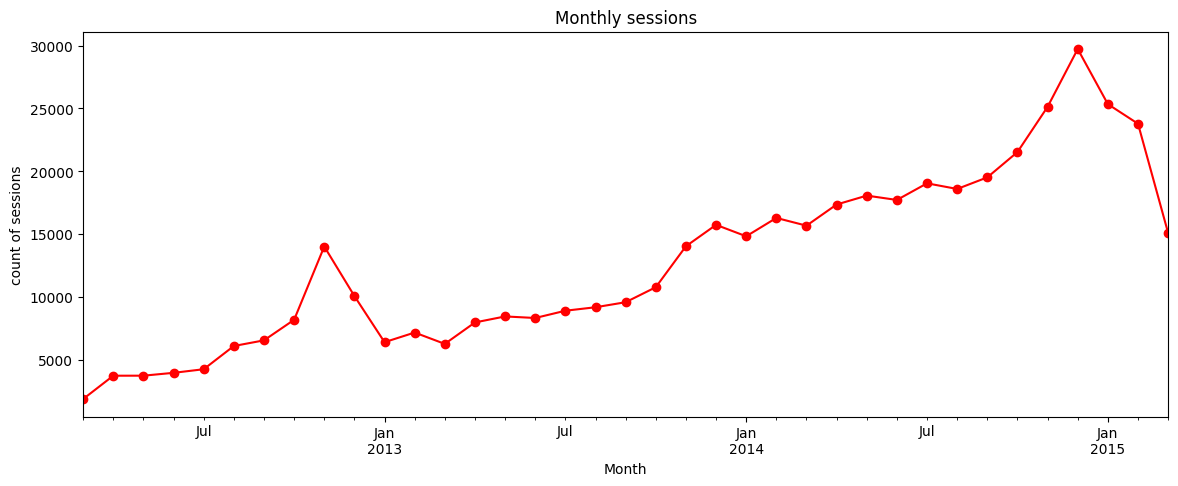

In [ ]:
plt.figure(figsize=(14,5))
monthly_sessions.plot(kind='line', marker='o', color='red')
plt.title('Monthly sessions')
plt.xlabel('Month')
plt.ylabel('count of sessions')

monthly orders

In [ ]:
orders['created_at'] = pd.to_datetime(
    orders['created_at'],
    errors='coerce'
)

In [ ]:
orders['month'] = orders['created_at'].dt.to_period('M')

In [ ]:
monthly_orders = (
    orders.groupby('month')['order_id']
    .nunique()
)

monthly_orders

,order_id
month,
2012-03,60
2012-04,99
2012-05,108
2012-06,140
2012-07,169
2012-08,228
2012-09,287
2012-10,371
2012-11,618


Text(0, 0.5, 'count of orders')

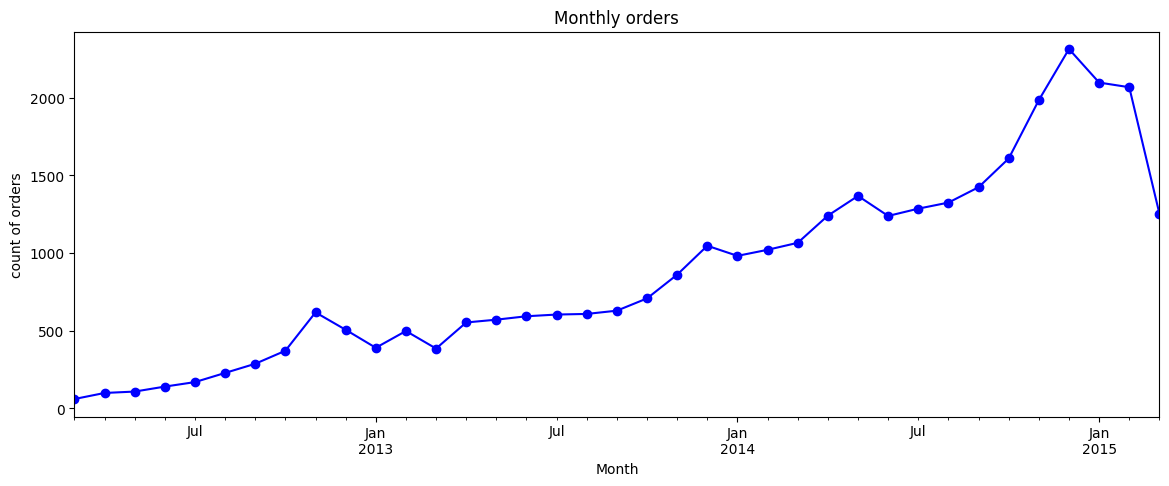

In [ ]:
plt.figure(figsize=(14,5))
monthly_orders.plot(kind='line', marker='o', color='blue')
plt.title('Monthly orders')
plt.xlabel('Month')
plt.ylabel('count of orders')

In [ ]:
conversion_rate = monthly_orders / monthly_sessions * 100


Text(0, 0.5, 'conversion %')

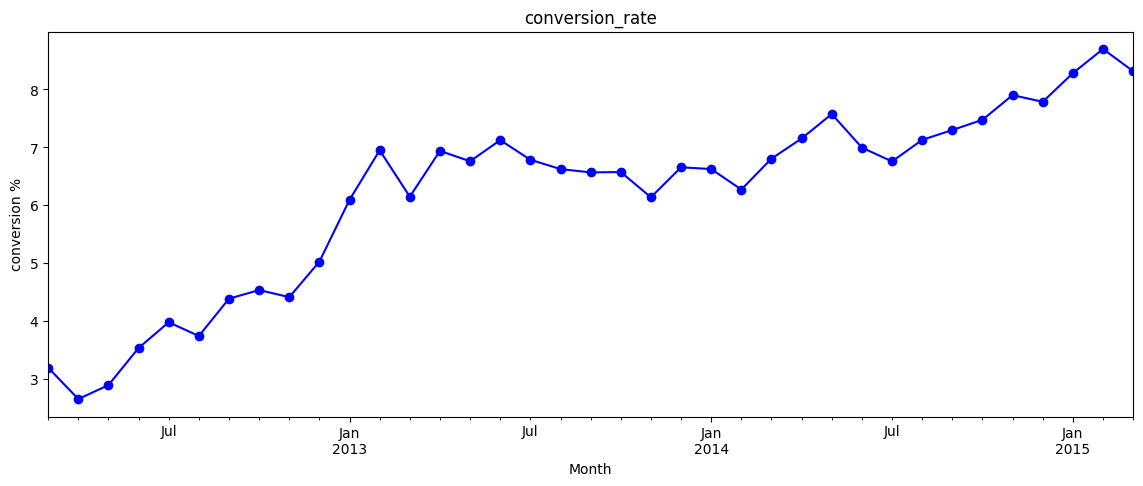

In [ ]:
plt.figure(figsize=(14,5))
conversion_rate.plot(kind='line', marker='o', color='blue')
plt.title('conversion_rate')
plt.xlabel('Month')
plt.ylabel('conversion %')

<Axes: xlabel='month'>

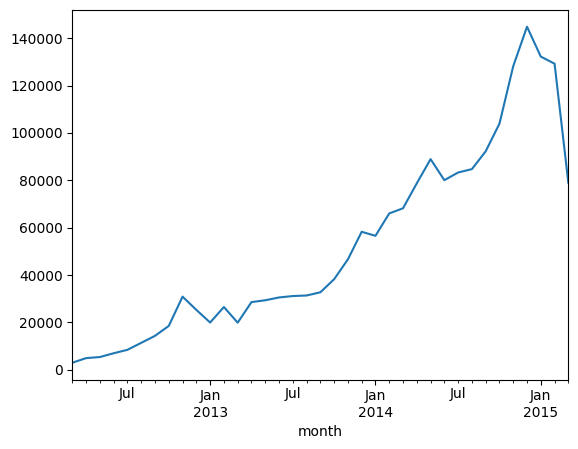

In [ ]:
monthly_revenue = (
    orders.groupby('month')['price_usd']
    .sum()
)

monthly_revenue.plot(kind='line')

In [ ]:
monthly_performance=pd.merge(monthly_sessions,monthly_orders,on='month',how='inner')

In [ ]:
monthly_performance=monthly_performance.merge(monthly_revenue,on='month',how='inner')

In [ ]:
monthly_performance['conversion_%']=conversion_rate = monthly_orders / monthly_sessions * 100
monthly_performance

,website_session_id,order_id,price_usd,conversion_%
month,,,,
2012-03,1879,60,2999.40,3.193188
2012-04,3734,99,4949.01,2.651312
2012-05,3736,108,5398.92,2.890792
2012-06,3963,140,6998.60,3.532677
2012-07,4249,169,8448.31,3.977406
2012-08,6097,228,11397.72,3.739544
2012-09,6546,287,14347.13,4.384357
2012-10,8183,371,18546.29,4.533790
2012-11,14011,618,30893.82,4.410820


Text(0.5, 1.0, 'monthly Performance')

<Figure size 1000x500 with 0 Axes>

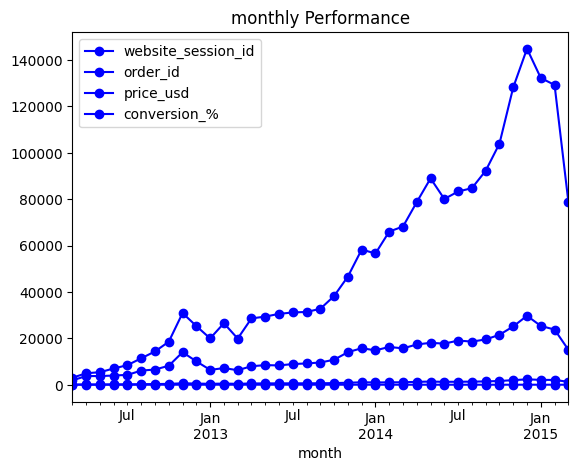

In [ ]:
plt.figure(figsize=(10,5))
monthly_performance.plot(kind='line', marker='o', color='blue')
plt.title('monthly Performance')


**key findings**
Traffic grew massively

Mar 2012: 1,879 sessions,
Dec 2014: 29,722 sessions,
That's about 15.8× growth.

Conversion efficiency improved

Mar 2012: 3.19% ,
Feb 2015: 8.70% ,
So the website wasn't just getting more traffic; a much larger percentage was converting.

Revenue grew strongly

Mar 2012: $2,999 ,
Dec 2014: $144,823,
Revenue growth is consistent with both higher traffic and higher conversion.

There is an apparent drop in March 2015
Feb 2015: $129,213 ,
Mar 2015: $78,951,
Sessions: 23,778 → 15,083,
Orders: 2,068 → 1,254,


Website traffic, orders, conversion rate, and revenue showed strong long-term improvement from 2012 to early 2015. Conversion increased from 3.19% in March 2012 to 8.70% in February 2015. The apparent March 2015 decline is excluded from trend interpretation because the dataset ends on March 19, making it a partial month.

**Seasonal / Year-over-Year Performance**

How does revenue change year-over-year, and are there seasonal patterns?

In [ ]:
orders['year'] = orders['created_at'].dt.year
orders['month_num'] = orders['created_at'].dt.month

In [ ]:
year_month_revenue = (
    orders.groupby(['year', 'month_num'])['price_usd']
    .sum()
    .reset_index()
)

year_month_revenue

,year,month_num,price_usd
0,2012,3,2999.40
1,2012,4,4949.01
2,2012,5,5398.92
3,2012,6,6998.60
4,2012,7,8448.31
5,2012,8,11397.72
6,2012,9,14347.13
7,2012,10,18546.29
8,2012,11,30893.82
9,2012,12,25294.94


In [ ]:
pivot_revenue = year_month_revenue.pivot(
    index='month_num',
    columns='year',
    values='price_usd'
)

pivot_revenue

year,2012,2013,2014,2015
month_num,,,,
1,NaN,19966.10,56568.89,132211.54
2,NaN,26515.02,66012.52,129212.94
3,2999.40,19896.15,68189.73,78951.07
4,4949.01,28584.47,78725.43,NaN
5,5398.92,29364.29,88935.27,NaN
6,6998.60,30544.07,80051.25,NaN
7,8448.31,31143.96,83288.55,NaN
8,11397.72,31373.92,84716.08,NaN
9,14347.13,32723.65,92232.49,NaN


In [ ]:
yoy_growth = (
    (pivot_revenue[2014] - pivot_revenue[2013])
    / pivot_revenue[2013]
    * 100
)

yoy_growth

,0
month_num,
1,183.324685
2,148.962739
3,242.728267
4,175.413293
5,202.868791
6,162.084424
7,167.430828
8,170.020705
9,181.852697


**Net Profitability After Refunds**

After accounting for refunds and COGS, which products actually generate the strongest profit?

In [ ]:
refund_by_item = refunds.groupby('order_item_id')['refund_amount_usd'].sum()
refund_by_item

,refund_amount_usd
order_item_id,
57,49.99
71,49.99
74,49.99
116,49.99
118,49.99
...,...
39813,49.99
39819,45.99
39860,49.99


In [ ]:
refund_analysis = order_items.merge(refund_by_item.reset_index(name='refund_amount_usd'),
    on='order_item_id',
    how='left'
)
refund_analysis

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,refund_amount_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,NaN
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,NaN
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,NaN
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,NaN
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,NaN
...,...,...,...,...,...,...,...,...
40020,40021,2015-03-19 04:10:43,32310,4,1,29.99,9.49,NaN
40021,40022,2015-03-19 05:27:28,32311,2,1,59.99,22.49,NaN
40022,40023,2015-03-19 05:27:28,32311,4,0,29.99,9.49,NaN
40023,40024,2015-03-19 05:35:57,32312,4,1,29.99,9.49,NaN


In [ ]:
refund_analysis['refund_amount_usd'] = (
    refund_analysis['refund_amount_usd'].fillna(0)
)

In [ ]:
refund_analysis.head()

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,refund_amount_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,0.0
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,0.0
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,0.0
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,0.0
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,0.0


In [ ]:
product_profitability = refund_analysis.groupby('product_id').agg(
    gross_revenue=('price_usd','sum'),
    total_cogs=('cogs_usd','sum'),
    total_refunds=('refund_amount_usd','sum')
)
product_profitability

,gross_revenue,total_cogs,total_refunds
product_id,,,
1,1211057.74,472164.74,61837.63
2,347702.04,130352.04,7738.71
3,229260.15,72232.65,13842.99
4,150489.82,47620.82,1919.36


In [ ]:
product_profitability['net_revenue'] =product_profitability['gross_revenue']-product_profitability['total_refunds']
product_profitability['net_profit']=product_profitability['net_revenue']-product_profitability['total_cogs']
product_profitability['profit_margin'] = product_profitability['net_profit']/product_profitability['net_revenue'] *100
product_profitability

,gross_revenue,total_cogs,total_refunds,net_revenue,net_profit,profit_margin
product_id,,,,,,
1,1211057.74,472164.74,61837.63,1149220.11,677055.37,58.914334
2,347702.04,130352.04,7738.71,339963.33,209611.29,61.657029
3,229260.15,72232.65,13842.99,215417.16,143184.51,66.468479
4,150489.82,47620.82,1919.36,148570.46,100949.64,67.947316


What does this tell the business?
**Product 1**

Generates by far the highest total profit.
But has the lowest profit margin.
It also has the largest refund amount.

**Product 4**

Generates the lowest total profit among the four.
But has the highest profit margin: 67.95%.
So it's more efficient per dollar of net revenue.

**Product 3**

Strong combination of profit and margin.
But its refund rate is relatively high, so refunds deserve attention.
The important business insight

**Product 1 is the biggest profit contributor, while Product 4 is the most profitable by margin.**

**------------Statistical analysis of refund behavior-------------**

Are higher-priced items more likely to be refunded?

In [ ]:
refund_analysis

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,refund_amount_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,0.0
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,0.0
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,0.0
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,0.0
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,0.0
...,...,...,...,...,...,...,...,...
40020,40021,2015-03-19 04:10:43,32310,4,1,29.99,9.49,0.0
40021,40022,2015-03-19 05:27:28,32311,2,1,59.99,22.49,0.0
40022,40023,2015-03-19 05:27:28,32311,4,0,29.99,9.49,0.0
40023,40024,2015-03-19 05:35:57,32312,4,1,29.99,9.49,0.0


In [ ]:
refund_analysis['is_refunded'] = (
    refund_analysis['refund_amount_usd'] > 0
).astype(int)
refund_analysis['is_refunded'].value_counts()

,count
is_refunded,
0,38294
1,1731


In [ ]:
refund_analysis.groupby('is_refunded')['price_usd'].agg(               #Compare prices between the two groups
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
is_refunded,,,,,,
0,38294,48.393249,49.99,8.121259,29.99,59.99
1,1731,49.300225,49.99,4.956015,29.99,59.99


refund probability at each price:

In [ ]:
refund_analysis.groupby('price_usd').agg(
    total_items=('is_refunded', 'size'),
    refunded_items=('is_refunded', 'sum')
).assign(
    refund_rate=lambda df:
        df['refunded_items'] / df['total_items'] * 100
)


,total_items,refunded_items,refund_rate
price_usd,,,
29.99,5018,64,1.275409
45.99,4985,301,6.038114
49.99,24226,1237,5.106084
59.99,5796,129,2.225673



**What does the data tell us?**

1. The highest-priced items do not have the highest refund rate.

Items priced at $59.99  have  a  2.23% refund rate, while $45.99 items have the highest rate at 6.04%.


2. The $45.99 price group needs investigation.

Its refund rate is about 4.7 times the $29.99 group's rate. We should investigate what is different about the products in these groups.



3. Price alone may not explain the difference.

The $45.99 items might belong to a particular product with quality issues, misleading descriptions, sizing problems, or other reasons for returns. These are hypotheses, not proven explanations.

In [ ]:
product_refund_analysis = refund_analysis.groupby('product_id').agg(        #: Calculate refund rates by product
    total_items=('order_item_id', 'count'),
    refunded_items=('is_refunded', 'sum')
)

product_refund_analysis['refund_rate'] = (
    product_refund_analysis['refunded_items']
    / product_refund_analysis['total_items'] * 100
)

product_refund_analysis.sort_values(
    'refund_rate', ascending=False
)


,total_items,refunded_items,refund_rate
product_id,,,
3,4985,301,6.038114
1,24226,1237,5.106084
2,5796,129,2.225673
4,5018,64,1.275409


Product 3 has the highest refund rate: 6.04%.



Product 4 has the lowest refund rate: 1.28%.



The most expensive product, Product 2, does not have the highest refund rate.



Since each price corresponds to a different product, we cannot separate the effect of price from the effect of product using these results.

**We'll use a chi-square test of independence to examine whether refund status (refunded or not refunded) is associated with product identity.**

Why this test?
- Product identity is categorical.
- Refund status is categorical.
- We have counts for each combination.
- The sample counts are large enough for the test's expected-count requirement to be checked.


**Set up the hypotheses**

**Null hypothesis (\(H_0\))**: Refund status and product identity are independent; refund rates do not differ across products in the underlying population.



**Alternative hypothesis (\(H_1\))**: Refund status and product identity are associated; at least one product's underlying refund rate differs.

In [ ]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    refund_analysis['product_id'],
    refund_analysis['is_refunded']
)

print(contingency_table)


is_refunded      0     1
product_id              
1            22989  1237
2             5667   129
3             4684   301
4             4954    64


In [ ]:
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)
print("\nExpected counts:")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
).round(2))


Chi-square statistic: 245.59508945640133
P-value: 5.868289005008526e-53
Degrees of freedom: 3

Expected counts:
is_refunded         0        1
product_id                    
1            23178.27  1047.73
2             5545.33   250.67
3             4769.41   215.59
4             4800.98   217.02


**P-value 5.87 × 10⁻⁵³**

Chi-square statistic  245.60

Degrees of freedom   3

Significance level  0.05

**Decision: Reject the null hypothesis.**

**Conclusion:** There is strong statistical evidence of an association between product identity and refund status.

**1. Cramér's V formula
\[{V=\sqrt{\frac{\chi^2}{n(k-1)}}}
\]**


Where:
- \(V\) = Cramér's V (strength of association)
- \(\chi^2\) = chi-square statistic
- \(n\) = total number of observations
- \(k\) = smaller number of rows or columns in the contingency table


**Chi-square statistic and p-value tell us whether there is evidence of an association.**



**Cramér's V tells us how strong that association is.**

In [ ]:
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print("Cramer's V:", cramers_v)


Cramer's V: 0.0783328935379561


result Says  **0.07833**, indicates a small overall association between product identity and refund status. It does not establish that the product or its price causes refunds.

**Business finding:** Product 3 has the highest observed refund rate (6.04%), while Product 4 has the lowest (1.28%).

In [ ]:
website_pageviews.shape


(1188124, 5)

In [ ]:
website_sessions.shape

(472871, 10)